In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Configuração de estilo
plt.style.use('ggplot')

# 1. Carregar dados do Our World in Data (OWID)
url = "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv"
print("Baixando dados do OWID... (isso pode levar alguns segundos)")
df_full = pd.read_csv(url)

# 2. Filtrar para França e colunas de interesse
country = "France"
df = df_full[df_full['location'] == country].copy()
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')

# Vamos pegar um recorte temporal onde houve as ondas principais (ex: 2020 a 2022)
# Isso ajuda a visualização e o ajuste não ficar "pesado" demais
start_date = '2020-03-01'
end_date = '2022-06-01'
mask = (df['date'] >= start_date) & (df['date'] <= end_date)
data = df.loc[mask].reset_index(drop=True)

# 3. Preparar vetores para o modelo
# Usamos média móvel de 7 dias para 'new_cases' para suavizar o ruído de final de semana
y_daily_real = data['new_cases'].rolling(window=7).mean().fillna(0).values
y_total_real = data['total_cases'].values

# Corrigir NaNs no total (preencher com o anterior)
y_total_real = pd.Series(y_total_real).fillna(method='ffill').fillna(0).values

# População da França (aprox 67.5 mi)
N = 67_500_000 
t_days = np.arange(len(y_daily_real))

print(f"Dados carregados para {country}: {len(t_days)} dias.")

Baixando dados do OWID... (isso pode levar alguns segundos)
Dados carregados para France: 823 dias.


C:\Users\pedro\AppData\Local\Temp\ipykernel_18664\2682782945.py:33: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  y_total_real = pd.Series(y_total_real).fillna(method='ffill').fillna(0).values


In [11]:
# --- 1. MODELO SIR CLÁSSICO ---
def sir_step(S, I, R, N, beta, gamma):
    new_inf = (beta * S * I) / N
    new_rec = gamma * I
    
    S_next = max(0, S - new_inf)
    I_next = max(0, I + new_inf - new_rec)
    R_next = R + new_rec
    return S_next, I_next, R_next, new_inf

def solve_sir(t, beta, gamma):
    S = np.zeros(len(t)); I = np.zeros(len(t)); R = np.zeros(len(t))
    Daily = np.zeros(len(t))
    
    # Inicialização
    I[0] = y_daily_real[0] if y_daily_real[0] > 0 else 100
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):
        S[i+1], I[i+1], R[i+1], Daily[i+1] = sir_step(S[i], I[i], R[i], N, beta, gamma)
        
    return S, I, R, Daily, (I + R) # SIR usa I+R como acumulado

# Wrapper para o otimizador
def fit_sir(t, beta, gamma):
    _, _, _, _, accumulated = solve_sir(t, beta, gamma)
    return accumulated


# --- 2. MODELO SIRS (Perda de Imunidade) ---
def sirs_step(S, I, R, N, beta, gamma, xi):
    new_inf = (beta * S * I) / N
    new_rec = gamma * I
    new_susc = xi * R # Perda de imunidade
    
    S_next = max(0, S - new_inf + new_susc)
    I_next = max(0, I + new_inf - new_rec)
    R_next = max(0, R + new_rec - new_susc)
    return S_next, I_next, R_next, new_inf

def solve_sirs(t, beta, gamma, xi):
    S = np.zeros(len(t)); I = np.zeros(len(t)); R = np.zeros(len(t))
    C = np.zeros(len(t)) # Contador Acumulado
    Daily = np.zeros(len(t))
    
    I[0] = y_daily_real[0] if y_daily_real[0] > 0 else 100
    C[0] = I[0]
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):
        S[i+1], I[i+1], R[i+1], Daily[i+1] = sirs_step(S[i], I[i], R[i], N, beta, gamma, xi)
        C[i+1] = C[i] + Daily[i+1]
        
    return S, I, R, Daily, C

def fit_sirs(t, beta, gamma, xi):
    _, _, _, _, accumulated = solve_sirs(t, beta, gamma, xi)
    return accumulated


# --- 3. MODELO DINÂMICO (Beta Variável) ---
# Número de nós para interpolação do Beta (controla a "flexibilidade" das ondas)
NUM_NODES = 15 
x_nodes = np.linspace(0, len(t_days)-1, NUM_NODES)

def solve_dynamic(t, gamma, xi, betas_array):
    S = np.zeros(len(t)); I = np.zeros(len(t)); R = np.zeros(len(t))
    C = np.zeros(len(t))
    Daily = np.zeros(len(t))
    
    I[0] = y_daily_real[0] if y_daily_real[0] > 0 else 100
    C[0] = I[0]
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):
        # Interpola o Beta do dia
        beta_t = np.interp(i, x_nodes, betas_array)
        
        # Usa a lógica do SIRS step com o beta variável
        S[i+1], I[i+1], R[i+1], Daily[i+1] = sirs_step(S[i], I[i], R[i], N, beta_t, gamma, xi)
        C[i+1] = C[i] + Daily[i+1]
        
    return S, I, R, Daily, C

def fit_dynamic(t, gamma, xi, *betas):
    # O *betas coleta todos os argumentos extras em uma lista
    _, _, _, _, accumulated = solve_dynamic(t, gamma, xi, betas)
    return accumulated

In [12]:
print("Otimizando Modelo 1: SIR...")
# Chutes iniciais: beta=0.1, gamma=0.05
popt_sir, _ = curve_fit(fit_sir, t_days, y_total_real, p0=[0.15, 0.05], bounds=(0, [1, 1]))

print("Otimizando Modelo 2: SIRS...")
# Chutes: beta=0.15, gamma=0.05, xi=0.01 (perda de imunidade lenta)
popt_sirs, _ = curve_fit(fit_sirs, t_days, y_total_real, p0=[0.15, 0.05, 0.001], bounds=(0, [1, 1, 0.1]))

print(f"Otimizando Modelo 3: Dinâmico ({NUM_NODES} nós)...")
# Precisamos passar 2 parâmetros fixos + NUM_NODES betas
initial_guess = [0.1, 0.01] + [0.2] * NUM_NODES
# Limites: gamma e xi entre 0 e 1; betas entre 0 e 2
lower_bounds = [0, 0] + [0] * NUM_NODES
upper_bounds = [1, 0.1] + [3.0] * NUM_NODES

popt_dyn, _ = curve_fit(fit_dynamic, t_days, y_total_real, p0=initial_guess, bounds=(lower_bounds, upper_bounds), maxfev=10000)

print("Ajustes concluídos!")
print(f"SIR -> Beta: {popt_sir[0]:.4f}, Gamma: {popt_sir[1]:.4f}")
print(f"SIRS -> Beta: {popt_sirs[0]:.4f}, Xi: {popt_sirs[2]:.4f}")
print(f"Dinâmico -> Xi: {popt_dyn[1]:.4f} (Beta varia no tempo)")

Otimizando Modelo 1: SIR...
Otimizando Modelo 2: SIRS...
Otimizando Modelo 3: Dinâmico (15 nós)...
Ajustes concluídos!
SIR -> Beta: 0.0594, Gamma: 0.0427
SIRS -> Beta: 0.6283, Xi: 0.1000
Dinâmico -> Xi: 0.0000 (Beta varia no tempo)


In [13]:
# 1. Rodar SIR com ótimos
S_sir, I_sir, R_sir, Daily_sir, Acc_sir = solve_sir(t_days, *popt_sir)

# 2. Rodar SIRS com ótimos
S_sirs, I_sirs, R_sirs, Daily_sirs, Acc_sirs = solve_sirs(t_days, *popt_sirs)

# 3. Rodar Dinâmico com ótimos
gamma_dyn, xi_dyn = popt_dyn[0], popt_dyn[1]
betas_dyn = popt_dyn[2:] # O resto são os betas
S_dyn, I_dyn, R_dyn, Daily_dyn, Acc_dyn = solve_dynamic(t_days, gamma_dyn, xi_dyn, betas_dyn)

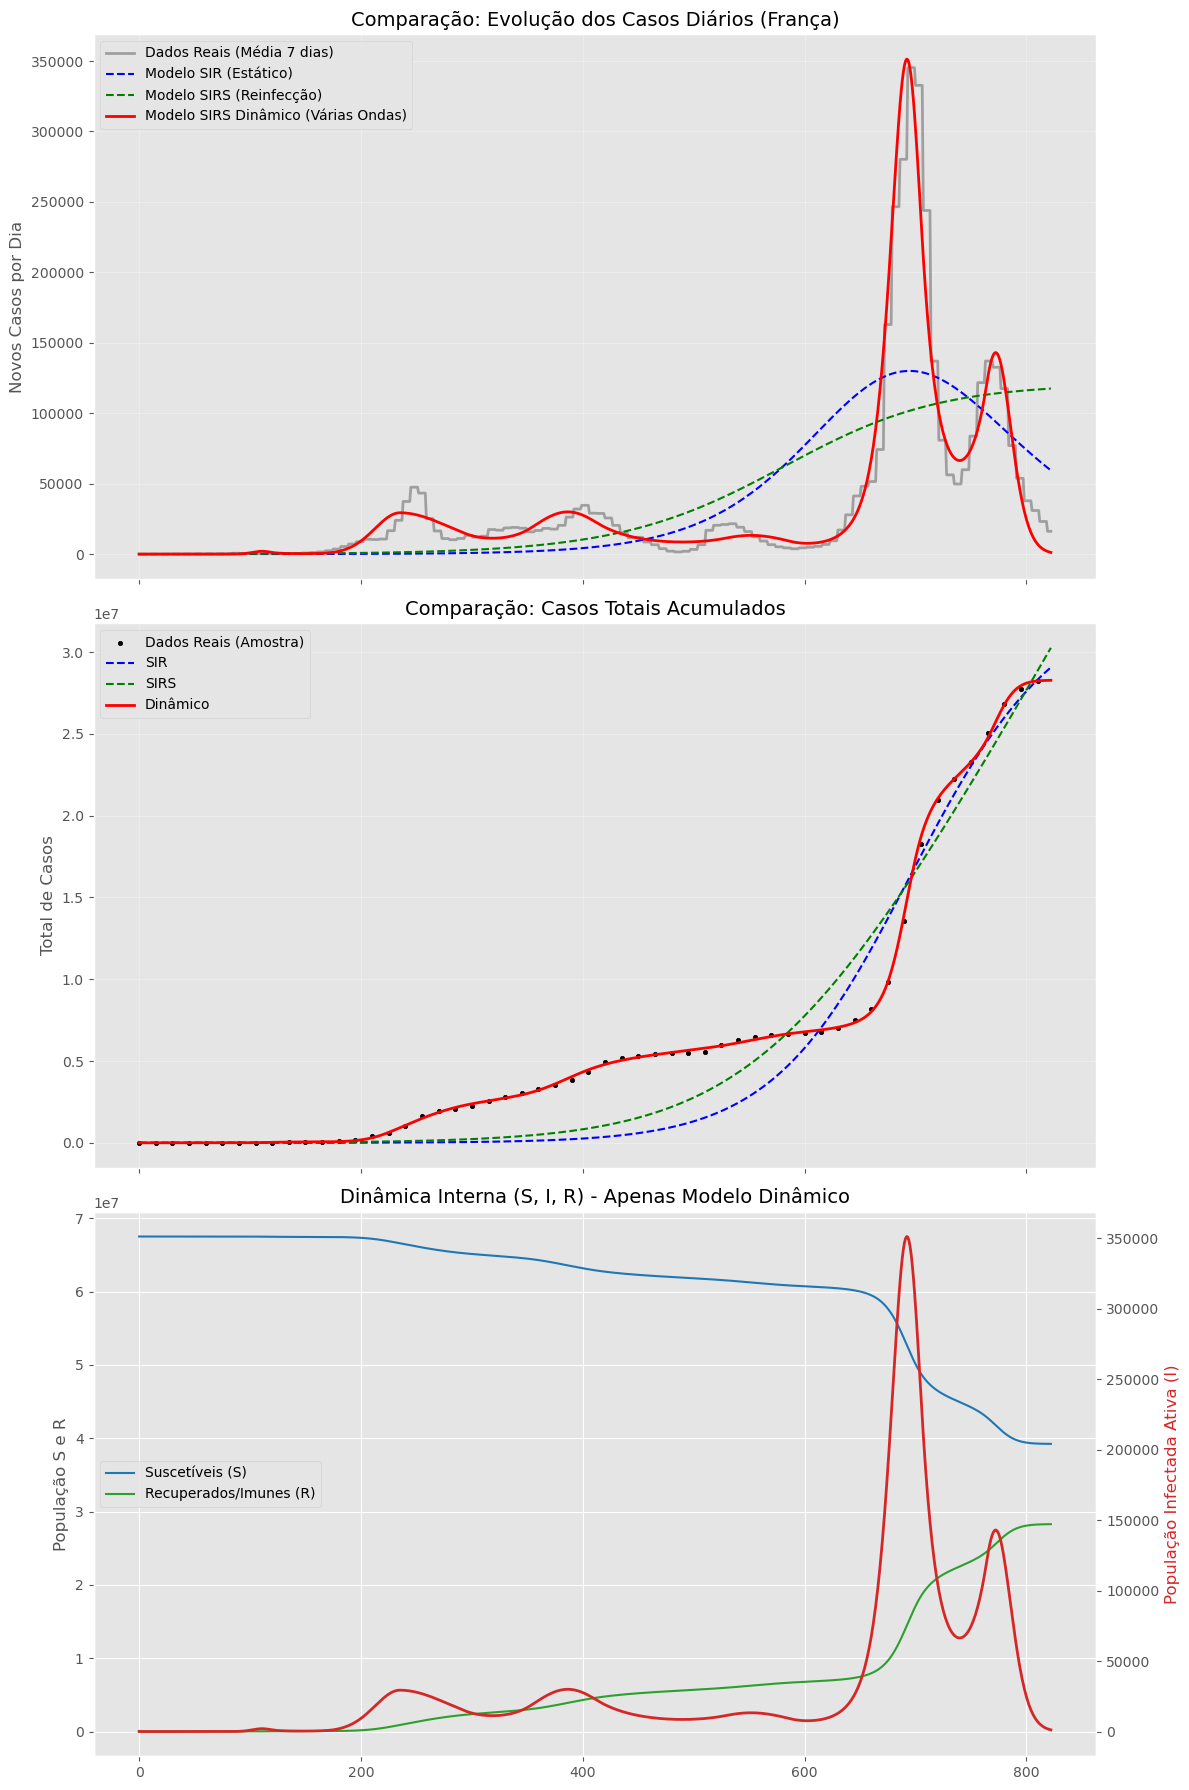

In [14]:
fig, ax = plt.subplots(3, 1, figsize=(12, 18), sharex=True)

# --- GRÁFICO 1: Casos Diários (Daily Cases) ---
ax[0].set_title("Comparação: Evolução dos Casos Diários (França)", fontsize=14)
# Dados Reais (Barra cinza ou linha pontilhada)
ax[0].plot(t_days, y_daily_real, color='black', alpha=0.3, label='Dados Reais (Média 7 dias)', linewidth=2)

# Modelos
ax[0].plot(t_days, Daily_sir, label='Modelo SIR (Estático)', linestyle='--', color='blue')
ax[0].plot(t_days, Daily_sirs, label='Modelo SIRS (Reinfecção)', linestyle='--', color='green')
ax[0].plot(t_days, Daily_dyn, label='Modelo SIRS Dinâmico (Várias Ondas)', color='red', linewidth=2)
ax[0].set_ylabel("Novos Casos por Dia")
ax[0].legend()
ax[0].grid(True, alpha=0.3)

# --- GRÁFICO 2: Casos Totais (Cumulative) ---
ax[1].set_title("Comparação: Casos Totais Acumulados", fontsize=14)
ax[1].scatter(t_days[::15], y_total_real[::15], color='black', s=10, label='Dados Reais (Amostra)') # Plotar menos pontos para limpar

ax[1].plot(t_days, Acc_sir, label='SIR', color='blue', linestyle='--')
ax[1].plot(t_days, Acc_sirs, label='SIRS', color='green', linestyle='--')
ax[1].plot(t_days, Acc_dyn, label='Dinâmico', color='red', linewidth=2)
ax[1].set_ylabel("Total de Casos")
ax[1].legend()
ax[1].grid(True, alpha=0.3)

# --- GRÁFICO 3: Dinâmica SIR (S, I, R) ---
# Vamos plotar apenas o do Modelo Dinâmico pois é o mais rico visualmente
ax[2].set_title(f"Dinâmica Interna (S, I, R) - Apenas Modelo Dinâmico", fontsize=14)

# Normalizando por milhão ou total para caber na escala
ax[2].plot(t_days, S_dyn, label='Suscetíveis (S)', color='tab:blue')
ax[2].plot(t_days, R_dyn, label='Recuperados/Imunes (R)', color='tab:green')
# Infectados geralmente é muito menor que S e R, vamos usar eixo gêmeo ou multiplicar para visualizar a forma
ax[2].set_ylabel("População S e R")
ax[2].legend(loc='center left')

ax2_twin = ax[2].twinx()
ax2_twin.plot(t_days, I_dyn, label='Infectados Ativos (I) - Eixo Dir.', color='tab:red', linewidth=2)
ax2_twin.set_ylabel("População Infectada Ativa (I)", color='tab:red')
ax2_twin.grid(False)

# Ajustes finais
plt.xlabel("Dias desde Março 2020")
plt.tight_layout()
plt.show()